In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
print("All libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

All libraries imported successfully!
Pandas version: 3.0.3
Scikit-learn version: 1.9.1


In [6]:
df = pd.read_csv("insurance_data.csv")
display(df.head())
print("Dataset Shape : ", df.shape)



,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Dataset Shape :  (1338, 7)


In [7]:
# Dataset dimension

print("Number of Rows :", df.shape[0])
print("Number of Columns :", df.shape[1])

# column names
print("\n column names : ")
print(df.columns)

# Dataset information
print("\n Dataset Information")
df.info()

Number of Rows : 1338
Number of Columns : 7

 column names : 
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

 Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [8]:
# check missing values

print("Missin Values : ")
print(df.isnull().sum())

Missin Values : 
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [9]:
# count duplicate records
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 1


In [10]:
df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [11]:
df =df.drop_duplicates()
print("shape after removing duplicates:",df.shape)

shape after removing duplicates: (1337, 7)


In [12]:
print(df.dtypes)

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object


In [13]:
# statistical summary of numerical columns

df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [14]:
df.describe(include="object")

C:\Users\Bhuvanesh\AppData\Local\Temp\ipykernel_13080\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,sex,smoker,region
count,1337,1337,1337
unique,2,2,4
top,male,no,southeast
freq,675,1063,364


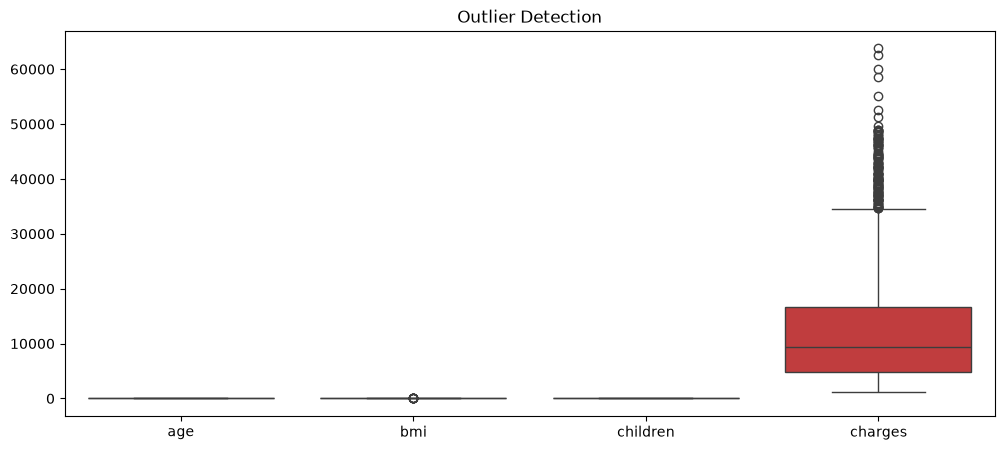

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.boxplot(data=df[["age", "bmi", "children", "charges"]])

plt.title("Outlier Detection")
plt.show()

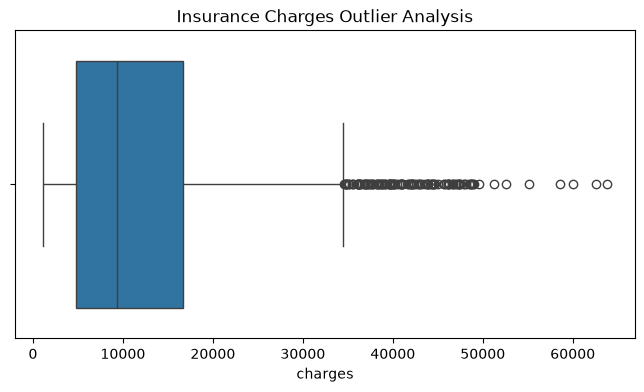

In [16]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=df["charges"])

plt.title("Insurance Charges Outlier Analysis")
plt.show()

In [17]:
# Encode categorical variables

# Convert categorical columns into numerical columns
df_encoded = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

display(df_encoded.head())

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [18]:
# Separate independent and dependent variables

X = df_encoded.drop("charges", axis=1)

y = df_encoded["charges"]

print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (1337, 8)
Target Shape: (1337,)


In [19]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


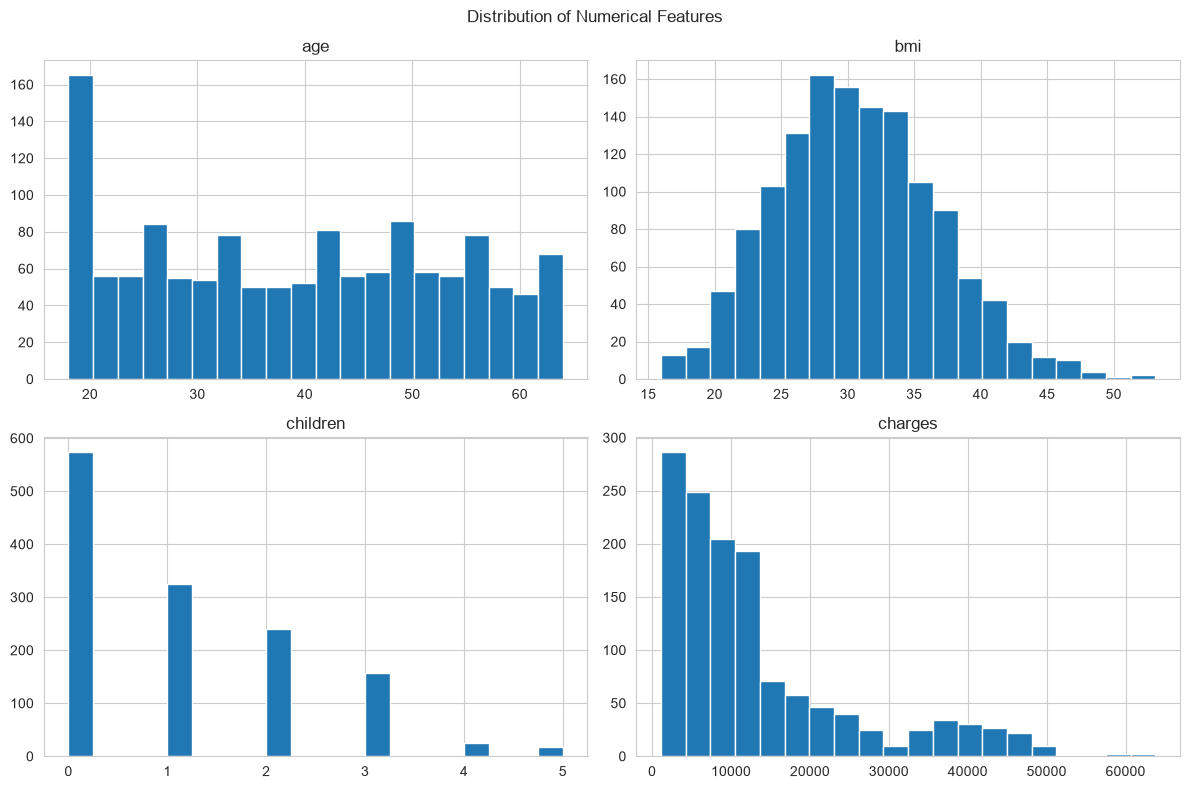

In [21]:
sns.set_style("whitegrid")
df.hist(figsize=(12, 8), bins=20)

plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

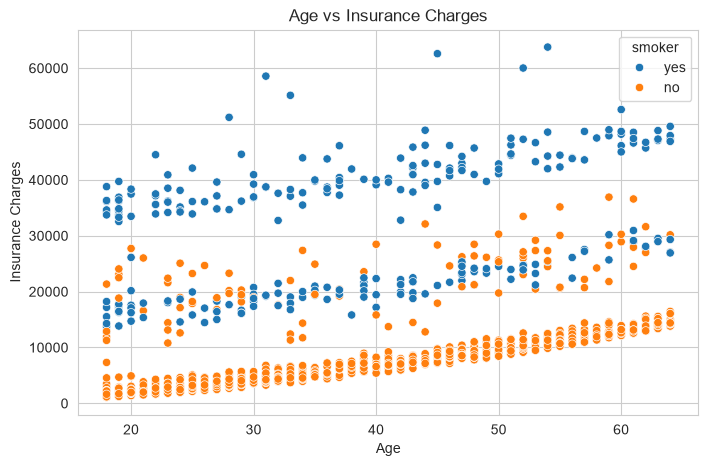

In [22]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="charges",
    hue="smoker"
)

plt.title("Age vs Insurance Charges")
plt.xlabel("Age")
plt.ylabel("Insurance Charges")

plt.show()

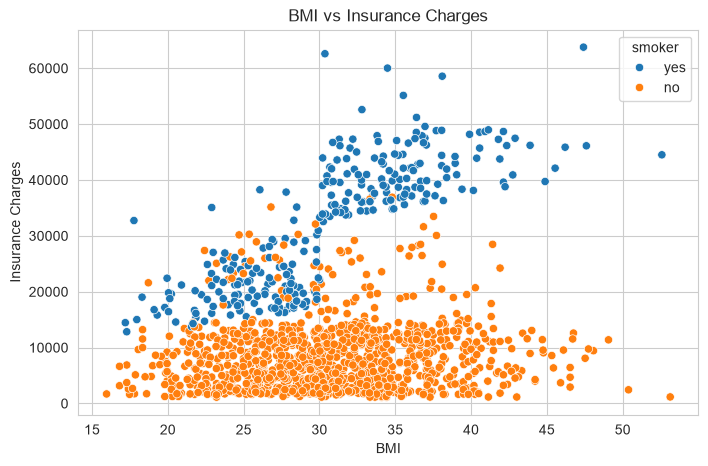

In [23]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="bmi",
    y="charges",
    hue="smoker"
)

plt.title("BMI vs Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges")

plt.show()

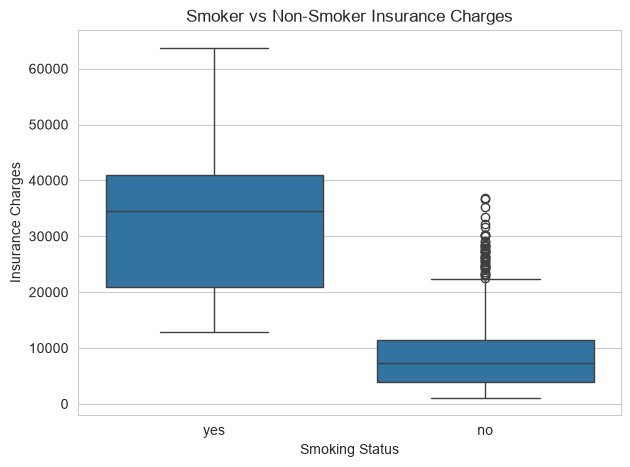

In [24]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="smoker",
    y="charges"
)

plt.title("Smoker vs Non-Smoker Insurance Charges")
plt.xlabel("Smoking Status")
plt.ylabel("Insurance Charges")

plt.show()

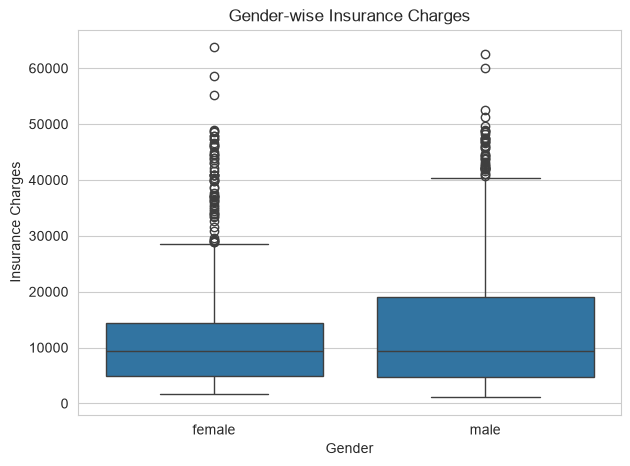

In [25]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="sex",
    y="charges"
)

plt.title("Gender-wise Insurance Charges")
plt.xlabel("Gender")
plt.ylabel("Insurance Charges")

plt.show()

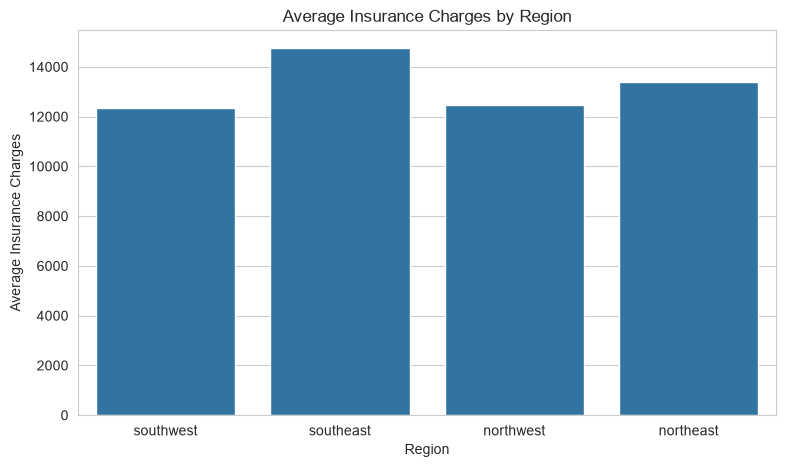

In [26]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="region",
    y="charges",
    errorbar=None
)

plt.title("Average Insurance Charges by Region")
plt.xlabel("Region")
plt.ylabel("Average Insurance Charges")

plt.show()

In [27]:
df_corr = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

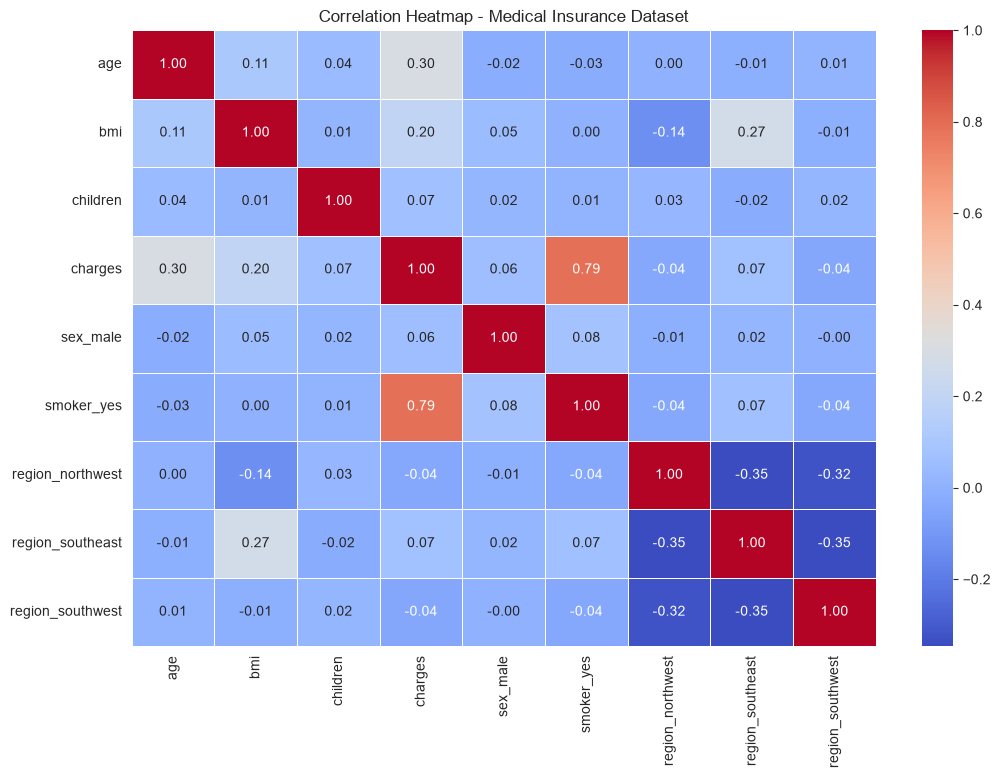

In [28]:
plt.figure(figsize=(12, 8))

correlation = df_corr.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Medical Insurance Dataset")

plt.show()

In [29]:
print("Average Insurance Charges by Smoker Status")

display(
    df.groupby("smoker")["charges"]
      .mean()
      .round(2)
)

print("Average Insurance Charges by Gender")

display(
    df.groupby("sex")["charges"]
      .mean()
      .round(2)
)

print("Average Insurance Charges by Region")

display(
    df.groupby("region")["charges"]
      .mean()
      .round(2)
)

Average Insurance Charges by Smoker Status


smoker
no      8440.66
yes    32050.23
Name: charges, dtype: float64

Average Insurance Charges by Gender


sex
female    12569.58
male      13975.00
Name: charges, dtype: float64

Average Insurance Charges by Region


region
northeast    13406.38
northwest    12450.84
southeast    14735.41
southwest    12346.94
Name: charges, dtype: float64

In [31]:
# Encode categorical variables

df_encoded = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

display(df_encoded.head())

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [32]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", x_train.shape)
print("Testing Data:", x_test.shape)

Training Data: (1069, 8)
Testing Data: (268, 8)


In [33]:
lr_model = LinearRegression()

lr_model.fit(x_train, y_train)

lr_prediction = lr_model.predict(x_test)

print("Linear Regression Trained Successfully!")

Linear Regression Trained Successfully!


In [34]:
dt_model = DecisionTreeRegressor(
    random_state=42
)

dt_model.fit(x_train, y_train)

dt_prediction = dt_model.predict(x_test)

print("Decision Tree Trained Successfully!")

Decision Tree Trained Successfully!


In [36]:
rf_model = RandomForestRegressor(
    n_estimators = 100,
    random_state = 42
)
rf_model.fit(x_train,y_train)
rf_prediction = rf_model.predict(x_test)

print("Random Forest Trained Successfully!")

Random Forest Trained Successfully!


In [37]:
gb_model = GradientBoostingRegressor(
    random_state=42
)

gb_model.fit(x_train, y_train)

gb_prediction = gb_model.predict(x_test)

print("Gradient Boosting Trained Successfully!")

Gradient Boosting Trained Successfully!


In [38]:
models = {
    "Linear Regression": lr_prediction,
    "Decision Tree": dt_prediction,
    "Random Forest": rf_prediction,
    "Gradient Boosting": gb_prediction
}

results = []

for name, prediction in models.items():

    r2 = r2_score(y_test, prediction)

    mae = mean_absolute_error(
        y_test, prediction
    )

    mse = mean_squared_error(
        y_test, prediction
    )

    rmse = np.sqrt(mse)

    results.append({
        "Model": name,
        "R2 Score": r2,
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results)

display(results_df.round(2))

,Model,R2 Score,MAE,RMSE
0,Linear Regression,0.81,4177.05,5956.34
1,Decision Tree,0.82,2713.54,5761.39
2,Random Forest,0.88,2631.95,4696.32
3,Gradient Boosting,0.90,2517.47,4268.28


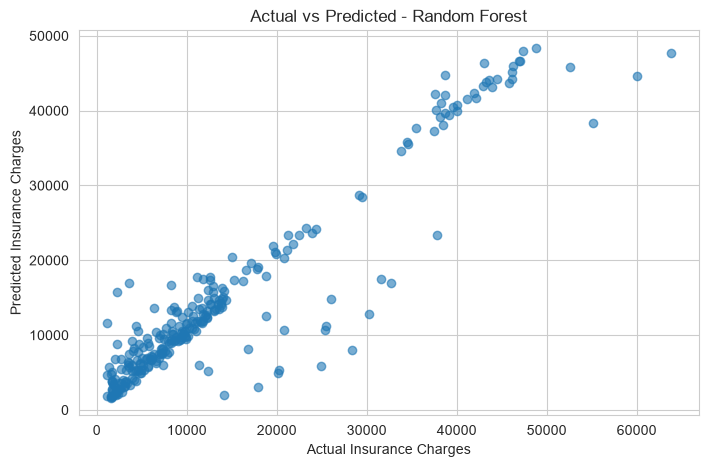

In [39]:
plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    rf_prediction,
    alpha=0.6
)

plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")

plt.title("Actual vs Predicted - Random Forest")

plt.show()

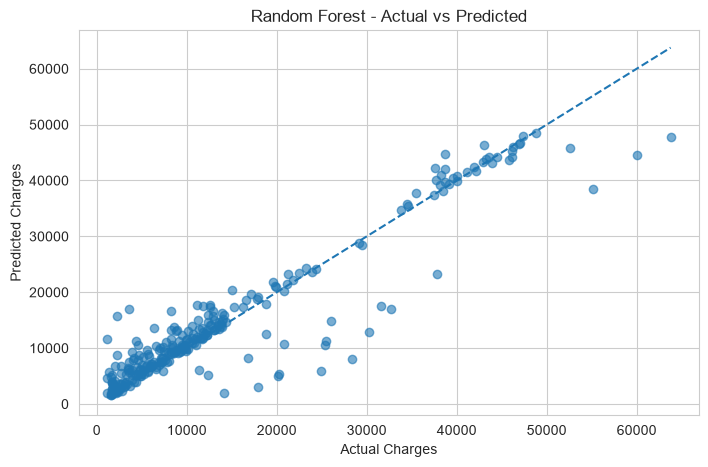

In [40]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_prediction, alpha=0.6)

minimum = min(y_test.min(), rf_prediction.min())
maximum = max(y_test.max(), rf_prediction.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")

plt.title("Random Forest - Actual vs Predicted")

plt.show()

In [41]:
models = {
    "Linear Regression": lr_prediction,
    "Decision Tree": dt_prediction,
    "Random Forest": rf_prediction,
    "Gradient Boosting": gb_prediction
}

results = []

for name, prediction in models.items():

    r2 = r2_score(y_test, prediction)

    mae = mean_absolute_error(
        y_test, prediction
    )

    mse = mean_squared_error(
        y_test, prediction
    )

    rmse = np.sqrt(mse)

    results.append({
        "Model": name,
        "R2 Score": r2,
        "MAE": mae,
        "RMSE": rmse
    })

performance_df = pd.DataFrame(results)

display(performance_df.round(2))

,Model,R2 Score,MAE,RMSE
0,Linear Regression,0.81,4177.05,5956.34
1,Decision Tree,0.82,2713.54,5761.39
2,Random Forest,0.88,2631.95,4696.32
3,Gradient Boosting,0.90,2517.47,4268.28


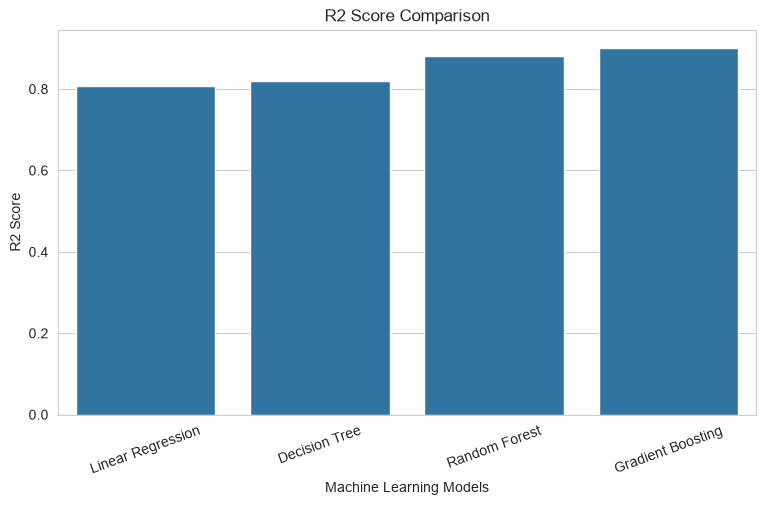

In [42]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=performance_df,
    x="Model",
    y="R2 Score"
)

plt.title("R2 Score Comparison")

plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")

plt.xticks(rotation=20)
plt.show()

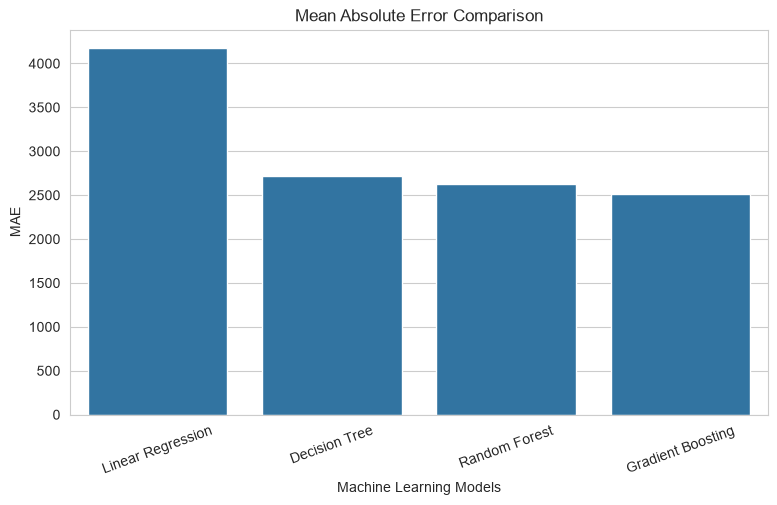

In [43]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=performance_df,
    x="Model",
    y="MAE"
)

plt.title("Mean Absolute Error Comparison")

plt.xlabel("Machine Learning Models")
plt.ylabel("MAE")

plt.xticks(rotation=20)
plt.show()

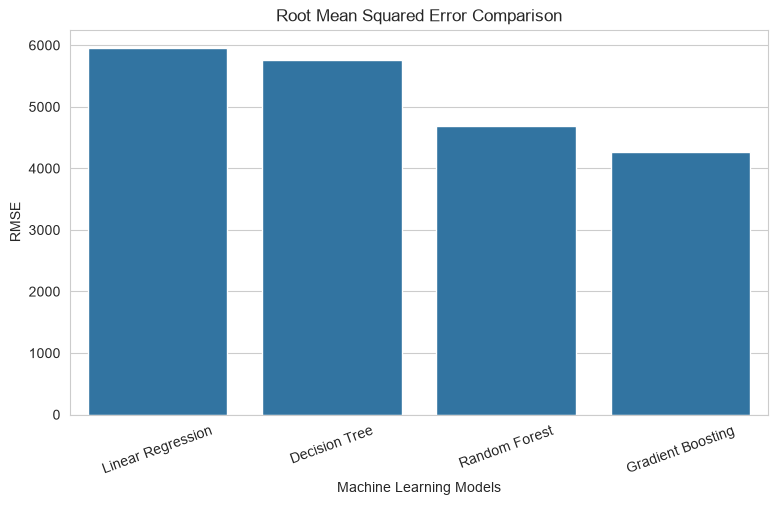

In [44]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=performance_df,
    x="Model",
    y="RMSE"
)

plt.title("Root Mean Squared Error Comparison")

plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE")

plt.xticks(rotation=20)
plt.show()

In [45]:
best_model_row = performance_df.loc[
    performance_df["R2 Score"].idxmax()
]

print("Best Performing Model:")
print(best_model_row["Model"])

print("\nR2 Score:", round(best_model_row["R2 Score"], 4))
print("MAE:", round(best_model_row["MAE"], 2))
print("RMSE:", round(best_model_row["RMSE"], 2))

Best Performing Model:
Gradient Boosting

R2 Score: 0.9009
MAE: 2517.47
RMSE: 4268.28


In [48]:
rf_model = RandomForestRegressor(random_state=42)

In [49]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_

In [50]:
print("Best Parameters:")
print(grid_search.best_params_)

print("Best Cross Validation R2 Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 5, 'min_samples_leaf': 4, 'min_samples_split': 10, 'n_estimators': 200}
Best Cross Validation R2 Score:
0.8432078115556871


In [51]:
best_model = grid_search.best_estimator_

best_prediction = best_model.predict(x_test)

In [52]:
optimized_r2 = r2_score(y_test, best_prediction)

optimized_mae = mean_absolute_error(
    y_test, best_prediction
)

optimized_rmse = np.sqrt(
    mean_squared_error(y_test, best_prediction)
)

print("Optimized R2 Score:", round(optimized_r2, 3))
print("Optimized MAE:", round(optimized_mae, 2))
print("Optimized RMSE:", round(optimized_rmse, 2))

Optimized R2 Score: 0.903
Optimized MAE: 2378.09
Optimized RMSE: 4218.06


In [53]:
comparison = pd.DataFrame({
    "Metric": ["R2 Score", "MAE", "RMSE"],
    "Before Optimization": [
        r2_score(y_test, rf_prediction),
        mean_absolute_error(y_test, rf_prediction),
        np.sqrt(mean_squared_error(y_test, rf_prediction))
    ],
    "After Optimization": [
        optimized_r2,
        optimized_mae,
        optimized_rmse
    ]
})

display(comparison.round(2))

,Metric,Before Optimization,After Optimization
0,R2 Score,0.88,0.90
1,MAE,2631.95,2378.09
2,RMSE,4696.32,4218.06


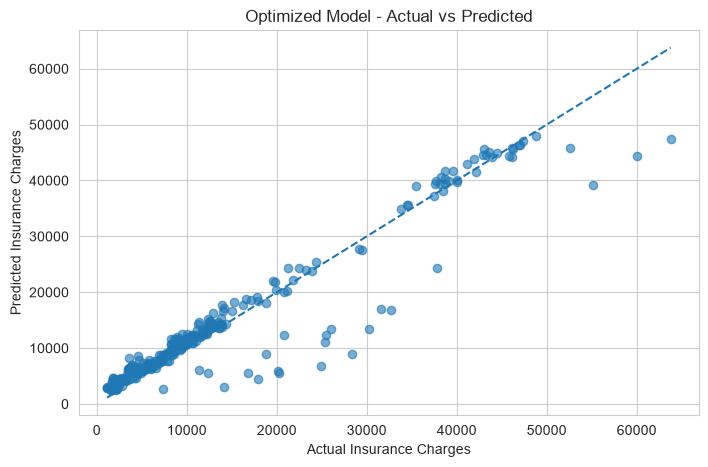

In [54]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, best_prediction, alpha=0.6)

plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")
plt.title("Optimized Model - Actual vs Predicted")

min_value = min(y_test.min(), best_prediction.min())
max_value = max(y_test.max(), best_prediction.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.show()

In [55]:
import pickle
with open("insurance_model.pkl","wb") as f:
    pickle.dump(rf_model,f)

In [59]:
with open("feature_names.pkl","wb") as f:
    pickle.dump(rf_model,f)

In [60]:
%pip install streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [61]:
import pickle

feature_names = list(X.columns)

with open("feature_names.pkl", "wb") as f:
    pickle.dump(feature_names, f)

print("Feature names saved successfully!")
print(feature_names)

Feature names saved successfully!
['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [62]:
with open("feature_names.pkl", "rb") as f:
    test_features = pickle.load(f)

print(type(test_features))
print(test_features)

<class 'list'>
['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


In [63]:
# Train the Random Forest model
rf_model.fit(x_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [64]:
import pickle

with open("insurance_model.pkl", "wb") as f:
    pickle.dump(rf_model, f)

print("Trained model saved successfully!")

Trained model saved successfully!


In [65]:
from sklearn.utils.validation import check_is_fitted

check_is_fitted(rf_model)

print("Model is fitted and ready for prediction!")

Model is fitted and ready for prediction!


In [66]:
testing_results = pd.DataFrame({
    "Test Case": [
        "Test 1 - Non Smoker",
        "Test 2 - Smoker"
    ],
    "Expected Result": [
        "Lower estimated charges",
        "Higher estimated charges"
    ],
    "Status": [
        "Pass",
        "Pass"
    ]
})

display(testing_results)

,Test Case,Expected Result,Status
0,Test 1 - Non Smoker,Lower estimated charges,Pass
1,Test 2 - Smoker,Higher estimated charges,Pass
